# SILLA — 02 · Content-Based Recommendation System & Evaluation
**Owner:** Amr Badr · Data Science & Recommendation
**نظام توصيات قائم على المحتوى + اقتراح وصفات بديلة + تقييم الجودة**

## How it works
Each recipe is described by four content blocks; similarity is a weighted sum of block similarities:

| Block | Representation | Similarity | Weight |
|---|---|---|---|
| Ingredients | TF-IDF over ingredient presence (rare ingredients weigh more than salt) | cosine | 0.55 |
| Ingredient mix | share of ingredients per category (meat, vegetables, dairy …) | cosine | 0.10 |
| Category / cuisine | dish type and cuisine | exact match | 0.20 / 0.05 |
| Practical | log cost per serving, log total time, difficulty, number of ingredients (scaled 0–1) | 1 − mean abs. difference | 0.10 |

On top of the similarity, `alternatives()` and `recommend()` apply user preferences:
**cheaper** (only cheaper dishes + savings bonus), **diet** (vegan / vegetarian / pescatarian), **excluded ingredients**
(allergies, dislikes — English or Egyptian Arabic names), **max cost per serving**, **max time**, and the **pantry**
(bonus for dishes that use what the user already has; salt, pepper, oil and water are assumed).
Style variants of the same dish are never recommended for each other, and only one recipe per dish is returned.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "SILLA_Data_Engineering").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from SILLA_Data_Science.data_loader import FIGURES_DIR, build_recipe_table, load_tables, unique_recipes

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

# Chart style: one accent colour, quiet axes, light grid
ACCENT, ACCENT_2, ACCENT_3, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

In [2]:
from SILLA_Data_Science.recommender import ContentBasedRecommender, Weights
tables = load_tables()
rec = ContentBasedRecommender().fit(build_recipe_table(), tables)
show = ["recipe_id", "recipe_name_en", "category", "similarity", "est_cost_per_serving", "cost_change_pct", "shared_ingredients"]
def title(rid):
    r = rec.recipes.set_index("recipe_id").loc[rid]
    print(f"Query: {rid} · {r.recipe_name_en} / {r.recipe_name_ar} · {r.category} · {r.est_cost_per_serving:.1f} EGP per serving")

## 1. Similar recipes ("more like this")

In [3]:
title("R0002"); rec.similar_recipes("R0002", k=5)[show]

Query: R0002 · Egyptian Koshari / كشري مصري بالدقة والصلصة والبصل المقرمش · Main Course · 27.8 EGP per serving


,recipe_id,recipe_name_en,category,similarity,est_cost_per_serving,cost_change_pct,shared_ingredients
0,R0009,Mahshi Cabbage Rolls,Main Course,0.5972,20.90,-24.7,"Cumin, Egyptian White Rice, Fine Salt, Ground Coriander,..."
1,R0041,Street Koshari-Style Pasta Tagine,Main Course,0.5805,44.90,61.7,"Cumin, Fine Salt, Garlic, Strained Tomato Puree, Vegetab..."
2,R0024,Egyptian Moussaka With Minced Beef,Main Course,0.5798,47.27,70.3,"Cumin, Fine Salt, Garlic, Strained Tomato Puree, Vegetab..."
3,R0016,Alexandrian Beef Liver,Main Course,0.5575,86.01,209.8,"Cumin, Fine Salt, Garlic, Ground Coriander, Vegetable Co..."
4,R0023,Egyptian Rice Kofta With Potato Stew,Main Course,0.5563,56.61,103.9,"Cumin, Egyptian White Rice, Fine Salt, Garlic, Strained ..."


In [4]:
title("R0001"); rec.similar_recipes("R0001", k=5)[show]

Query: R0001 · Macaroni Béchamel / مكرونة بشاميل باللحمة المفرومة · Main Course · 66.2 EGP per serving


,recipe_id,recipe_name_en,category,similarity,est_cost_per_serving,cost_change_pct,shared_ingredients
0,R0130,Cannelloni With Beef And Béchamel,Main Course,0.7767,69.46,4.9,"All-Purpose Flour, Black Pepper, Butter, Fine Salt, Grou..."
1,R0114,Egyptian Moussaka With Béchamel,Main Course,0.7541,66.19,-0.0,"All-Purpose Flour, Black Pepper, Butter, Fine Salt, Grou..."
2,R0111,Mashed Potato Beef Gratin,Main Course,0.7288,38.16,-42.4,"Black Pepper, Butter, Eggs, Fine Salt, Ground Beef, Toma..."
3,R0041,Street Koshari-Style Pasta Tagine,Main Course,0.7073,44.90,-32.2,"Black Pepper, Fine Salt, Ground Beef, Penne Pasta, Tomat..."
4,R0036,Baked Goulash With Minced Beef,Main Course,0.7044,35.47,-46.4,"All-Purpose Flour, Black Pepper, Eggs, Fine Salt, Ground..."


In [5]:
# Why are two recipes similar? Contribution of each block to the final score
pd.DataFrame({"Macaroni Béchamel vs Moussaka With Béchamel": rec.explain("R0001", "R0114"),
              "Macaroni Béchamel vs Koshari": rec.explain("R0001", "R0002")})

,Macaroni Béchamel vs Moussaka With Béchamel,Macaroni Béchamel vs Koshari
ingredients,0.3220,0.0459
ingredient_mix,0.0846,0.0662
category,0.2000,0.2000
cuisine,0.0500,0.0500
numeric,0.0974,0.0892
total,0.7541,0.4514


## 2. Alternative recipes by cost, ingredients and preferences

In [6]:
print("Cheaper alternatives:"); title("R0003")
rec.alternatives("R0003", k=5, cheaper=True)[show]

Cheaper alternatives:
Query: R0003 · Molokhia With Chicken / ملوخية خضراء بالدجاج والتقلية · Main Course · 50.3 EGP per serving


,recipe_id,recipe_name_en,category,similarity,est_cost_per_serving,cost_change_pct,shared_ingredients
0,R0029,Upper Egyptian Bamya Weika,Main Course,0.5880,17.08,-66.1,"Black Pepper, Dry Coriander, Fine Salt, Garlic, Ghee"
1,R0113,Chicken Liver And Gizzards With Pomegranate,Main Course,0.4985,20.68,-58.9,"Black Pepper, Fine Salt, Garlic, Ghee, Yellow Onion"
2,R0025,Egyptian Taro Root With Swiss Chard,Main Course,0.4591,14.64,-70.9,"Black Pepper, Fine Salt, Garlic, Ghee"
3,R0015,Orzo Tagine With Minced Beef,Main Course,0.5250,31.04,-38.3,"Black Pepper, Fine Salt, Garlic, Ghee, Yellow Onion"
4,R0011,Mahshi Zucchini And Eggplant,Main Course,0.4521,20.44,-59.4,"Black Pepper, Fine Salt, Ghee, Yellow Onion"


In [7]:
print("Vegetarian alternatives to a meat dish:"); title("R0001")
rec.alternatives("R0001", k=5, diet="vegetarian", same_category=False)[show]

Vegetarian alternatives to a meat dish:
Query: R0001 · Macaroni Béchamel / مكرونة بشاميل باللحمة المفرومة · Main Course · 66.2 EGP per serving


,recipe_id,recipe_name_en,category,similarity,est_cost_per_serving,cost_change_pct,shared_ingredients
0,R0128,Crispy Fried Cauliflower In Egg Herb Batter,Main Course,0.5567,42.52,-35.8,"All-Purpose Flour, Eggs, Fine Salt, Vegetable Cooking Oi..."
1,R0037,Baked Goulash With Mixed Cheeses,Main Course,0.5426,30.88,-53.4,"All-Purpose Flour, Black Pepper, Eggs, Whole Milk"
2,R0042,Egyptian Feteer Meshaltet,Main Course,0.5016,10.95,-83.5,"All-Purpose Flour, Fine Salt, Vegetable Cooking Oil"
3,R0009,Mahshi Cabbage Rolls,Main Course,0.4987,20.90,-68.4,"Black Pepper, Fine Salt, Tomato Paste, Vegetable Cooking..."
4,R0002,Egyptian Koshari,Main Course,0.4514,27.76,-58.1,"Fine Salt, Vegetable Cooking Oil, Yellow Onion"


In [8]:
print("Without beef (allergy / dislike), using the Arabic word لحم:"); title("R0001")
print("Excluded:", sorted(rec.ingredients.loc[list(rec.resolve_ingredients(["لحم"])), "canonical_name_en"]))
rec.alternatives("R0001", k=5, exclude_ingredients=["لحم"])[show]

Without beef (allergy / dislike), using the Arabic word لحم:
Query: R0001 · Macaroni Béchamel / مكرونة بشاميل باللحمة المفرومة · Main Course · 66.2 EGP per serving
Excluded: ['Beef Liver', 'Beef Shank', 'Beef Sirloin Steak', 'Beef Stew Cubes', 'Ground Beef', 'Lamb Meat Cubes', 'Minced Lamb', 'Oriental Sausage', 'Oxtail', 'Pastirma']


,recipe_id,recipe_name_en,category,similarity,est_cost_per_serving,cost_change_pct,shared_ingredients
0,R0039,Crispy Chicken Pane,Main Course,0.5847,68.67,3.7,"All-Purpose Flour, Black Pepper, Eggs, Fine Salt, Vegeta..."
1,R0034,Keshk Almazia With Chicken,Main Course,0.5725,51.61,-22.1,"All-Purpose Flour, Black Pepper, Fine Salt, Whole Milk, ..."
2,R0040,Negresco Chicken Pasta,Main Course,0.5693,70.64,6.7,"All-Purpose Flour, Black Pepper, Butter, Fine Salt, Whol..."
3,R0128,Crispy Fried Cauliflower In Egg Herb Batter,Main Course,0.5567,42.52,-35.8,"All-Purpose Flour, Eggs, Fine Salt, Vegetable Cooking Oi..."
4,R0030,Rural Stuffed Pigeon With Freekeh,Main Course,0.5510,115.90,75.0,"Black Pepper, Fine Salt, Ground Nutmeg, Yellow Onion"


In [9]:
print("What can I cook with what I have, under 30 EGP per serving?")
pantry = ["رز", "بصل", "طماطم", "عدس", "مكرونة", "ثوم"]
print("Pantry resolved to:", sorted(rec.ingredients.loc[list(rec.resolve_ingredients(pantry)), "canonical_name_en"]))
rec.recommend(pantry=pantry, max_cost_per_serving=30, k=5)[
    ["recipe_name_en", "category", "pantry_coverage", "missing_ingredients", "est_cost_per_serving"]]

What can I cook with what I have, under 30 EGP per serving?
Pantry resolved to: ['Basmati Rice', 'Brown Lentils', 'Egyptian White Rice', 'Elbow Macaroni', 'Fettuccine Pasta', 'Garlic', 'Penne Pasta', 'Red Onion', 'Red Split Lentils', 'Red Tomato', 'Spaghetti Pasta', 'Strained Tomato Puree', 'Tomato Paste', 'Yellow Onion']


,recipe_name_en,category,pantry_coverage,missing_ingredients,est_cost_per_serving
0,Creamy Tomato Basil Soup,Soup,0.667,"Butter, Extra Virgin Olive Oil, Heavy Cream",20.96
1,Syrian Garlic Toum,Appetizer,0.600,"Cornstarch, Lemon",9.80
2,Egyptian Koshari,Main Course,0.571,"Canned Chickpeas, Cumin, Ground Coriander, Hot Red Peppe...",27.76
3,Penne All'Arrabbiata,Main Course,0.571,"Extra Virgin Olive Oil, Hot Red Pepper Powder, Parmesan ...",29.31
4,Egyptian Red Lentil Soup With Vermicelli,Soup,0.545,"Carrot, Cumin, Ghee, Lemon, Vermicelli",10.61


In [10]:
print("User liked Koshari and Molokhia; vegan, under 45 minutes:")
rec.recommend(liked_recipe_ids=["R0002", "R0003"], diet="vegan", max_total_time=45, k=5)[
    ["recipe_name_en", "category", "score", "est_cost_per_serving", "total_time"]]

User liked Koshari and Molokhia; vegan, under 45 minutes:


,recipe_name_en,category,score,est_cost_per_serving,total_time
0,Egyptian Pickled Eggplants,Appetizer,0.3352,4.96,35
1,Spicy Stuffed Taameya,Breakfast,0.3190,56.80,35
2,Authentic Egyptian Taameya,Breakfast,0.2912,42.06,40
3,Boiled Beetroot Salad With Cumin,Salad,0.2675,10.48,45
4,Egyptian Baladi Salad,Salad,0.2675,5.87,15


## 3. Evaluation
There are no user ratings or purchases yet, so the recommender is evaluated **offline with content-based proxy metrics**.
Each of the 155 unique dishes is used once as a query, top-5 lists are scored and averaged.

| Metric | Meaning | Better |
|---|---|---|
| category_precision@5 | share of recommendations in the same dish category | ↑ |
| ingredient_jaccard@5 | ingredient overlap with the query | ↑ |
| description_sim@5 | TF-IDF similarity of the recipe **descriptions** — text the recommender never sees (independent judge) | ↑ |
| nDCG@5 (description) | ranking quality with description similarity as gain; duplicates get 0 | ↑ |
| cost_gap@5 | mean \|log(cost ratio)\| to the query | ↓ |
| diversity@5 | 1 − mean pairwise ingredient similarity inside the list | ↑ (balance) |
| duplicate_rate | share of suggestions that are just a style variant of the query | ↓ |
| catalog_coverage | share of dishes recommended at least once | ↑ |

In [11]:
from SILLA_Data_Science.evaluation import run_all
results = run_all(save=True)
comp = results["method_comparison"]
comp.round(3)

,category_precision,ingredient_jaccard,description_sim,ndcg_description,cost_gap,diversity,duplicate_rate,catalog_coverage
Random,0.276,0.153,0.044,0.187,1.014,0.889,0.000,0.994
Same category (random),0.994,0.236,0.081,0.350,0.686,0.810,0.000,1.000
Naive ingredient cosine (no variant filter),0.711,0.596,0.317,0.446,0.586,0.403,0.213,1.000
Ingredients only (TF-IDF),0.613,0.436,0.144,0.635,0.728,0.638,0.000,0.974
Hybrid content-based (SILLA),0.947,0.413,0.144,0.645,0.575,0.667,0.000,0.974


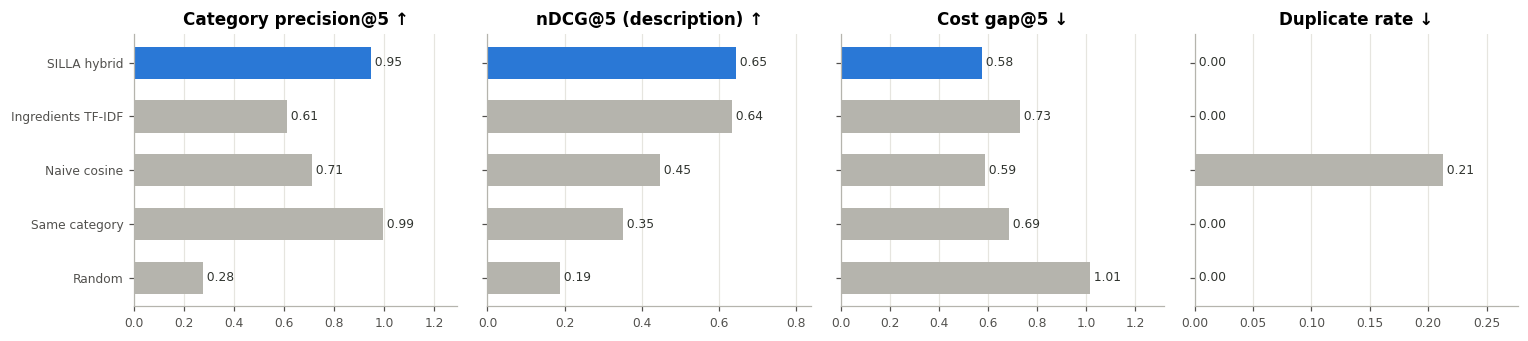

In [12]:
metrics = [("category_precision", "Category precision@5 ↑"), ("ndcg_description", "nDCG@5 (description) ↑"),
           ("cost_gap", "Cost gap@5 ↓"), ("duplicate_rate", "Duplicate rate ↓")]
labels = {"Random": "Random", "Same category (random)": "Same category", "Naive ingredient cosine (no variant filter)": "Naive cosine",
          "Ingredients only (TF-IDF)": "Ingredients TF-IDF", "Hybrid content-based (SILLA)": "SILLA hybrid"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, (m, t) in zip(axes, metrics):
    vals = comp[m].rename(index=labels)
    ax.barh(vals.index, vals.values, color=[ACCENT if i == "SILLA hybrid" else "#b5b4ad" for i in vals.index], height=0.6)
    for y, v in enumerate(vals.values):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=8, color="#30342f")
    ax.set_title(t); ax.grid(axis="y", visible=False); ax.set_xlim(0, max(vals.max() * 1.3, 0.1))
save(fig, "rec_method_comparison")

In [13]:
results["weight_sensitivity"].round(3)

,category_precision,ingredient_jaccard,description_sim,ndcg_description,cost_gap,diversity,duplicate_rate,catalog_coverage
ingredients 1.0,0.613,0.436,0.144,0.635,0.728,0.638,0.0,0.974
ingredients .7 / category .3,0.965,0.409,0.140,0.625,0.592,0.663,0.0,0.974
default (.55/.10/.20/.05/.10),0.947,0.413,0.144,0.645,0.575,0.667,0.0,0.974
ingredients .4 / category .3 / numeric .3,0.992,0.397,0.140,0.629,0.520,0.672,0.0,0.974
equal weights,0.950,0.387,0.137,0.622,0.551,0.693,0.0,0.981


In [14]:
sc = results["scenarios"]
sc[["queries", "success_rate", "avg_results", "constraint_compliance", "avg_similarity", "avg_cost_change_pct",
    "pantry_coverage_with_pantry", "pantry_coverage_without_pantry"]]

,queries,success_rate,avg_results,constraint_compliance,avg_similarity,avg_cost_change_pct,pantry_coverage_with_pantry,pantry_coverage_without_pantry
Unconstrained (same category),155.0,1.0000,4.97,1.0,0.6277,32.04,NaN,NaN
Cheaper alternative,155.0,0.9484,4.23,1.0,0.5648,-47.24,NaN,NaN
Vegetarian version of a non-vegetarian dish,88.0,1.0000,5.00,1.0,0.4846,-56.77,NaN,NaN
Exclude the key ingredient (allergy / dislike),155.0,1.0000,4.93,1.0,0.5977,29.64,NaN,NaN
Budget: max 30 EGP per serving,155.0,0.9290,4.61,1.0,0.5202,-27.64,NaN,NaN
Pantry-aware (8 random pantry items),155.0,1.0000,5.00,NaN,NaN,NaN,0.3707,0.3284


## 4. Conclusions
- **The hybrid recommender beats every baseline on ranking quality** (highest nDCG with description similarity as an
  independent judge, ≈ 3.4× random) while keeping **95% of suggestions in the same dish category** and the **closest price level** (lowest cost gap).
- **Naive ingredient cosine looks good on paper but is useless in practice:** about 21% of its suggestions are style
  variants of the query (the same dish with a different name). The family filter removes these completely (0%).
- **Ingredients alone** give high overlap but mix categories (61% same category: a dessert can be suggested for a main course);
  adding category, cost and time features fixes this with almost no loss in description similarity.
- **Preference constraints are always respected** (100% compliance for cheaper, vegetarian, excluded ingredient and budget).
  Cheaper alternatives save on average ≈ 47% per serving, and a cheaper option exists for ≈ 95% of dishes.
- **The pantry bonus raises the share of already-owned ingredients** in the suggestions; its weight can be tuned with real usage.
- **Limitations:** no user feedback yet (metrics are proxies); costs are partly imputed; small categories limit alternatives.
  Next step: log user clicks / cart additions and evaluate with Hit-Rate@K and precision on real interactions.